In [ ]:
import torch as torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_sample_image
from torch import nn
from torchvision import transforms as T
from torch.nn import functional as F
from functools import partial

In [ ]:
X = load_sample_image('china.jpg')
X_tensor = torch.tensor(X, dtype=torch.float).permute(2, 0, 1)/255
transform = T.Compose([
    T.CenterCrop(size=(200, 200)),
])
X_tensor = transform(X_tensor)
X_tensor.shape

torch.Size([3, 200, 200])

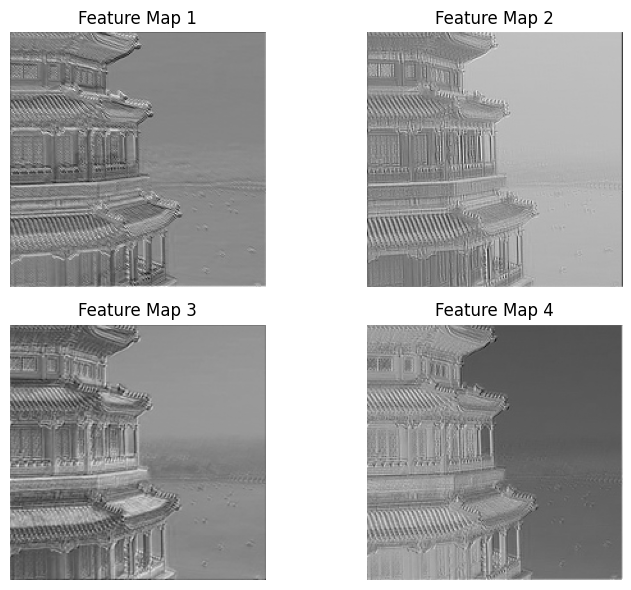

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

conv = nn.Conv2d(in_channels=3, out_channels=4, kernel_size=3, stride=1, padding='same').to(device)   #Padding = same only when stride =1 to match the dimension
feature_maps = conv(X_tensor.to(device))

fig, ax = plt.subplots(2, 2, figsize=(8, 6))
ax = ax.ravel()
for i in range(4):
    ax[i].imshow(feature_maps[i].detach().cpu().numpy(), cmap='gray')
    ax[i].set_title(f'Feature Map {i+1}')
    ax[i].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
conv.weight.shape, feature_maps.shape

(torch.Size([4, 3, 3, 3]), torch.Size([4, 200, 200]))

In [ ]:
my_conv = partial(nn.Conv2d, kernel_size=3, stride=1, padding='same')
conv_2 = my_conv(in_channels=4, out_channels=2).to(device)
# feature_maps = F.relu_(feature_maps)
feature_maps_2 = conv_2(feature_maps)
print(feature_maps_2.shape, conv_2.weight.shape)

torch.Size([2, 200, 200]) torch.Size([2, 4, 3, 3])


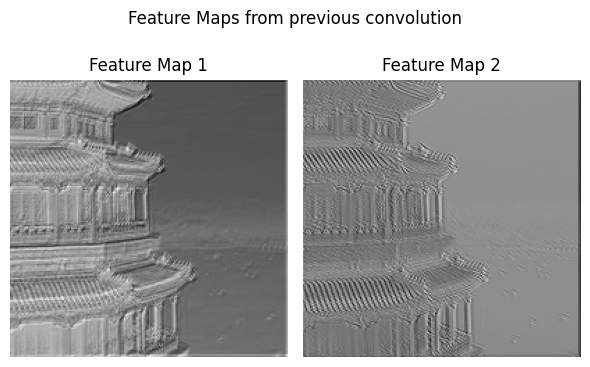

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(6, 4))
plt.suptitle('Feature Maps from previous convolution')
for i in range(2):
    ax[i].imshow(feature_maps_2[i].detach().cpu().numpy(), cmap='gray')
    ax[i].set_title(f'Feature Map {i+1}')
    ax[i].axis('off')
plt.tight_layout()
plt.show()

**Max pooling** slides a window (usually 2×2, stride 2) over each feature map and keeps only the largest value in each window.

- It is not a convolution: no weights, no multiplication, no sum.
- Each channel is pooled separately, so the channel count stays the same.
- With kernel 2 and stride 2, height and width are halved.
- The max keeps the strongest filter response in each window, so "the pattern is present around here" survives while exact position and weak responses are dropped.
- Benefits: fewer values for later layers, a larger receptive field, and some tolerance to small shifts.

In [ ]:
my_max_pool = partial(nn.MaxPool2d, kernel_size=2, stride=2)
my_max_pool = my_max_pool()

In [ ]:
#First taking my image
pool = my_max_pool(X_tensor)
print(pool.shape); print(X_tensor.shape)

torch.Size([3, 100, 100])
torch.Size([3, 200, 200])


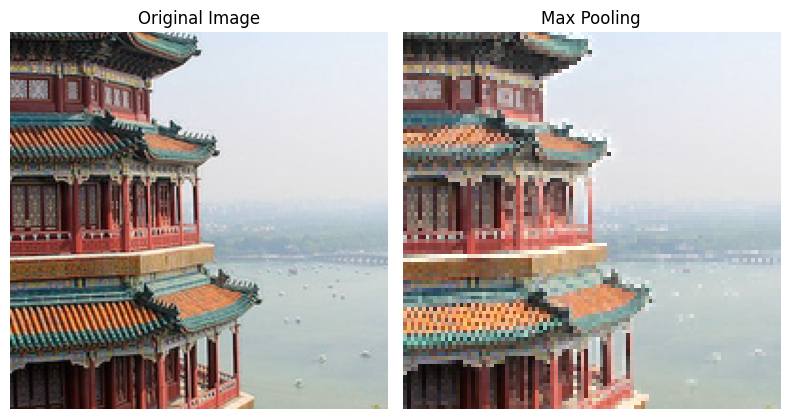

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(8, 6))
ax[0].imshow(X_tensor.permute(1, 2, 0).detach().cpu().numpy())
ax[0].set_title('Original Image')
ax[1].imshow(pool.permute(1, 2, 0).detach().cpu().numpy(), cmap='gray')
ax[1].set_title('Max Pooling')
ax[0].axis('off'); ax[1].axis('off')
plt.tight_layout()
plt.show()

torch.Size([2, 100, 100])


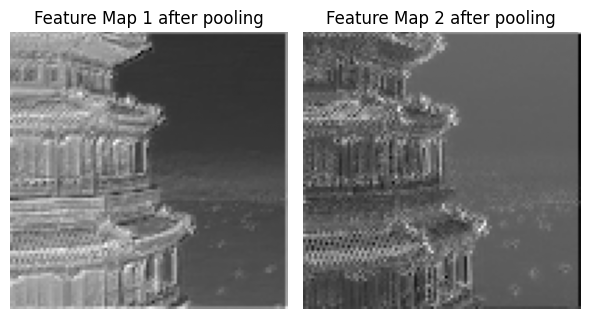

In [ ]:
my_max_pool = partial(nn.MaxPool2d, kernel_size=2, stride=2)
pool = my_max_pool()
pooling = pool(feature_maps_2)
print(pooling.shape)

fig, ax = plt.subplots(1, 2, figsize=(6, 4))
for i in range(2):
  ax[i].imshow(pooling[i].detach().cpu().numpy(), cmap='gray')
  ax[i].set_title(f'Feature Map {i+1} after pooling')
  ax[i].axis('off')
plt.tight_layout()
plt.show()

Translation invariance means the output doesn't change when the object moves in the image. A cat in the top-left should give the same "cat" answer as a cat in the bottom-right.

Equivariance: if the input shifts, the output shifts the same way. Conv layers have this. Shift the cat 5 pixels right, and the feature map's strong response also shifts 5 pixels right. Same kernel at every position makes this happen.
Invariance: if the input shifts, the output doesn't change at all. This is what you want at the end, for classification